# 14 — Linear Groups

**Primary source:** Michael Artin, *Algebra*, 2nd ed., Chapter 9, “Linear Groups,” §§9.1–9.8.

This notebook follows Artin’s concrete, geometric treatment of matrix groups. Code appears only where a numerical check or visualization clarifies the mathematics; it does not replace proof.

## Chapter structure
1. Classical linear groups
2. Spheres and stereographic projection
3. The special unitary group $SU(2)$
4. The rotation group $SO(3)$
5. One-parameter groups
6. Lie algebras
7. Translation in a group
8. Normal subgroups of $SL_2$

We assume familiarity with matrix operations, vector spaces, linear transformations, determinants, and groups. See notebooks **02_groups**, **03_linear_spaces**, and **13_grids_euclidean** for related material.

## 1. Classical linear groups

A **linear group** is a group of invertible matrices under matrix multiplication. Classical groups are often defined by equations expressing preservation of an algebraic or geometric structure.

### General and special linear groups
$$GL_n(F)=\{A\in M_n(F):\det A\ne0\},\qquad SL_n(F)=\{A\in GL_n(F):\det A=1\}.$$
The determinant measures oriented volume scaling. Over $\mathbb R$, elements of $SL_n$ preserve oriented volume but need not preserve lengths or angles.

### Orthogonal and unitary groups
$$O_n(\mathbb R)=\{A:A^TA=I\},\quad SO_n(\mathbb R)=\{A:A^TA=I,\det A=1\},$$
$$U_n(\mathbb C)=\{A:A^*A=I\},\quad SU_n(\mathbb C)=\{A:A^*A=I,\det A=1\}.$$
Here $A^*=\overline A^{\,T}$. Orthogonal and unitary matrices preserve inner products; the special groups additionally impose determinant one.

### Symplectic group
For $J=\begin{pmatrix}0&I\\-I&0\end{pmatrix}$,
$$Sp_{2n}(\mathbb R)=\{A\in GL_{2n}(\mathbb R):A^TJA=J\}.$$
It preserves a nondegenerate skew-symmetric bilinear form, not an inner product. This structure appears in Hamiltonian Mechanics (Symplectic Geometry, which explains the name).

**Examples / non-examples.** A planar rotation lies in $SO_2$. A reflection lies in $O_2$, but not $SO_2$, since its determinant is $-1$. A determinant-one shear lies in $SL_2(\mathbb R)$ but is generally not orthogonal. A singular matrix is never in $GL_n$.

### Code: distinguishing rotations, reflections, and shears

This cell checks determinant and orthogonality numerically. It demonstrates that preserving area (determinant one) and preserving lengths (orthogonality) are different properties.

In [1]:
import numpy as np

theta = np.pi / 5
R = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
F = np.array([[1., 0.], [0., -1.]])   # reflection
S = np.array([[1., 2.], [0., 1.]])    # shear
I = np.eye(2)
for name, A in {"rotation": R, "reflection": F, "shear": S}.items():
    print(name, "det =", round(np.linalg.det(A), 3), "orthogonal =", np.allclose(A.T @ A, I))

rotation det = 1.0 orthogonal = True
reflection det = -1.0 orthogonal = True
shear det = 1.0 orthogonal = False


## 2. Spheres and stereographic projection

The unit sphere is $S^n=\{x\in\mathbb R^{n+1}:\|x\|=1\}$. Artin’s geometric interlude prepares for $SU(2)$, whose underlying space is the 3-sphere. Stereographic projection identifies a sphere minus one point with Euclidean coordinate space. It illustrates how a curved space can be studied locally using ordinary coordinates.

A **great circle** is the intersection of a sphere with a plane through the origin. A latitude circle away from the equator is a small circle, not a great circle. Keep the distinction between the sphere as a space and any group operation it may carry: the group operation on $SU(2)$ is matrix multiplication.

## 3. The special unitary group $SU(2)$

$$SU(2)=\{P\in M_2(\mathbb C):P^*P=I,\det P=1\}.$$
Every element has the form
$$P=\begin{pmatrix}a&b\\-\overline b&\overline a\end{pmatrix},\qquad |a|^2+|b|^2=1.$$
Writing $a=x_0+ix_1$ and $b=x_2+ix_3$ identifies its underlying space with
$$x_0^2+x_1^2+x_2^2+x_3^2=1,$$
namely $S^3$. This is a statement about the topology of the set, not about addition being its group law.

A useful form is $P=\cos\theta I+\sin\theta A$, where $A$ is a suitable traceless skew-Hermitian matrix with $A^2=-I$. This generalizes the sine-cosine parameterization of the unit circle. $SU(2)$ is closely related to spatial rotations, with an important global two-to-one feature.

## 4. The rotation group $SO(3)$ and the double cover

$$SO(3)=\{R\in M_3(\mathbb R):R^TR=I,\det R=1\}.$$
Its elements are rotations of three-dimensional Euclidean space. There exists a homomorphism
$$\Phi:SU(2)\to SO(3),\qquad \Phi(P)(X)=PXP^{-1},$$
using conjugation on a three-dimensional real space of traceless skew-Hermitian matrices.

The key results are that $\Phi$ is surjective and
$$\ker\Phi=\{I,-I\},\qquad SO(3)\cong SU(2)/\{\pm I\}.$$
Thus $P$ and $-P$ encode the same rotation. The angle parameter in $SU(2)$ corresponds to twice that angle in $SO(3)$. The groups are closely related but are not isomorphic as topological groups.

**Reading Exercise:** Search (in your favorite search engine) about `Dirac's Belt Trick`.

### Code: an orbit under rotations
This visualization shows the orbit of a vector under rotations around the $z$-axis. It illustrates the action of $SO(3)$, not the covering map from $SU(2)$.

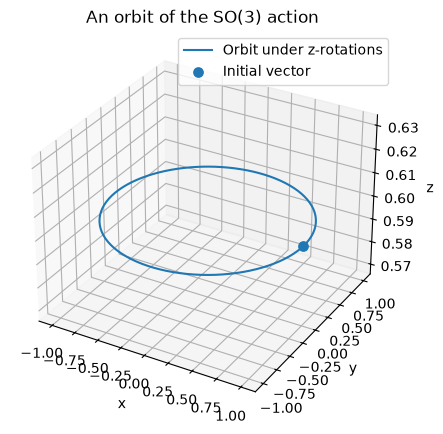

In [2]:
import matplotlib.pyplot as plt
angles = np.linspace(0, 2*np.pi, 200)
z = np.full_like(angles, 0.6)
x, y = np.cos(angles), np.sin(angles)
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection="3d")
ax.plot(x, y, z, label="Orbit under z-rotations")
ax.scatter([1], [0], [0.6], s=45, label="Initial vector")
ax.set(xlabel="x", ylabel="y", zlabel="z", title="An orbit of the SO(3) action")
ax.legend()
plt.show()

## 5. One-parameter groups and the matrix exponential

A one-parameter group is a differentiable homomorphism $\varphi:(\mathbb R,+)\to G$ with $\varphi(s+t)=\varphi(s)\varphi(t)$. For a fixed matrix $A$,
$$e^{tA}=I+tA+\frac{t^2A^2}{2!}+\cdots,\qquad e^{(s+t)A}=e^{sA}e^{tA}.$$
Every differentiable one-parameter subgroup of $GL_n$ is $e^{tA}$ for a unique $A=\varphi'(0)$.

The classical group constraints translate into conditions on $A$:
- $e^{tA}$ is orthogonal for all $t$ when $A^T=-A$.
- $e^{tA}$ is unitary for all $t$ when $A^*=-A$.
- $e^{tA}\in SL_n$ for all $t$ when $\operatorname{tr}A=0$, because $\det(e^{tA})=e^{t\operatorname{tr}A}$.

### Code: the generator of planar rotations
The next cell compares a matrix exponential with the usual rotation formula. It demonstrates how one infinitesimal matrix generates a continuous family of transformations.

In [3]:
from scipy.linalg import expm
A = np.array([[0., -1.], [1., 0.]])
for t in [0.0, 0.4, 1.0]:
    R_exp = expm(t*A)
    R_formula = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    print(f"t={t:.1f}: formulas agree =", np.allclose(R_exp, R_formula))

t=0.0: formulas agree = True
t=0.4: formulas agree = True
t=1.0: formulas agree = True


## 6. Lie algebras

The Lie algebra $\mathfrak g=\operatorname{Lie}(G)$ is the tangent space of a matrix group at the identity, represented by matrices. If $\gamma(t)\in G$, $\gamma(0)=I$, then $\gamma'(0)\in\mathfrak g$.

For the classical groups:
$$\mathfrak{so}(n)=\{A:A^T=-A\},\quad \mathfrak{sl}_n=\{A:\operatorname{tr}A=0\},$$
$$\mathfrak u(n)=\{A:A^*=-A\},\quad \mathfrak{su}(n)=\{A:A^*=-A,\operatorname{tr}A=0\}.$$
The Lie bracket is the matrix commutator $[A,B]=AB-BA$. It is bilinear, skew-symmetric, and satisfies the Jacobi identity
$$[A,[B,C]]+[B,[C,A]]+[C,[A,B]]=0.$$
The bracket records the failure of infinitesimal transformations to commute.

For example, $\mathfrak{so}(3)$ consists of skew-symmetric $3\times3$ matrices and has dimension three, matching the three degrees of freedom of a small spatial rotation. The Lie algebra is a vector space with a bracket; it is not simply another matrix group.

### Code: checking Lie algebra constraints

This numerical check illustrates that exponentiating a skew-symmetric matrix gives an orthogonal matrix, and exponentiating a trace-zero matrix gives determinant one. The general statements require proof beyond this example.

In [4]:
A_so = np.array([[0., -1., 0.], [1., 0., -2.], [0., 2., 0.]])
A_sl = np.array([[1., 2.], [0., -1.]])
Q, M = expm(0.3*A_so), expm(0.3*A_sl)
print("A_so skew-symmetric:", np.allclose(A_so.T, -A_so))
print("exp(0.3 A_so) orthogonal:", np.allclose(Q.T @ Q, np.eye(3)))
print("trace(A_sl):", np.trace(A_sl))
print("det(exp(0.3 A_sl)):", np.linalg.det(M))

A_so skew-symmetric: True
exp(0.3 A_so) orthogonal: True
trace(A_sl): 0.0
det(exp(0.3 A_sl)): 1.0


## 7. Translation in a group

For $P\in G$, left translation is $L_P:G\to G$, $L_P(Q)=PQ$. It is a homeomorphism with inverse $L_{P^{-1}}$. Since it carries the identity to $P$, every point of a group has the same topological local structure: the group is **homogeneous**.

Do not confuse left translation with a group homomorphism. Generally $L_P(QR)=PQR$ while $L_P(Q)L_P(R)=PQP R$, and these need not agree.

Artin uses homogeneity and the local behavior of the matrix exponential to motivate why closed subgroups of $GL_n$ are manifolds. The full proof uses topology and the local inverse of the exponential map.

## 8. Normal subgroups of $SL_2$ and simplicity

The center is $Z(G)=\{z\in G:zg=gz\text{ for every }g\in G\}$. A subgroup $N$ is normal when $gNg^{-1}=N$ for every $g\in G$; normal subgroups are used to form quotient groups.

Under suitable field assumptions, the center of $SL_2(F)$ is $\{\pm I\}$, and
$$PSL_2(F)=SL_2(F)/Z(SL_2(F))$$
is the projective special linear group. Artin studies when this quotient is simple. Field hypotheses matter: $PSL_2(\mathbb F_2)\cong S_3$ and $PSL_2(\mathbb F_3)\cong A_4$, so these small cases are not simple.

The proof strategy is instructive: use normality and conjugation to produce more elements, show elementary matrices lie in the subgroup, then use generation by elementary matrices to obtain the whole group. This connects explicit matrix calculations with global group structure.

## 9. Summary and conceptual connections

$$\text{matrix equations}\to\text{classical groups}\to\text{continuous paths}\to\text{Lie algebras}.$$

- **Algebra:** matrix groups are groups under multiplication.
- **Geometry:** $SU(2)$ has the underlying space $S^3$, and maps onto $SO(3)$ two-to-one.
- **Analysis:** one-parameter subgroups are described by matrix exponentials.
- **Infinitesimal structure:** Lie algebras linearize matrix groups at the identity.
- **Topology:** translations imply homogeneity; connectedness constrains subgroups.
- **Group structure:** normal subgroups and projective quotients lead to simplicity results.

Examples/non-examples: a reflection is orthogonal but not special orthogonal; a general matrix does not generate a one-parameter subgroup in a prescribed classical group; a Lie algebra is a vector space with a bracket, not generally a group under addition alone.

## Exercises

The following prompts are **paraphrases of selected exercises at the end of Artin, Chapter 9**. Consult the source for exact wording and notation.

### §9.1 — Classical linear groups
1. Investigate embedding $GL_n(\mathbb C)$ into $GL_{2n}(\mathbb R)$ by viewing a complex-linear map as a real-linear map.
2. Describe equations and path-connected components of the one-dimensional Lorentz group $O(1,1)$.
3. Prove symplectic matrices have determinant one and study the symplectic group's action on vectors.

### §9.2 — Spheres
4. Derive the inverse stereographic projection.
5. Relate complex lines in $\mathbb C^2$ to points on $S^2$, including the relation between orthogonal lines.

### §9.3 — $SU(2)$
6. Express multiplication in $SU(2)$ in its real-coordinate description.
7. Prove $SU(2)$ is homeomorphic to $S^3$.
8. Determine the centralizer of a specified element of $SU(2)$.

### §9.4 — $SO(3)$
9. Describe the orbits of $SO(3)$ acting by conjugation on skew-symmetric $3\times3$ matrices.
10. Prove the map $SU(2)\to SO(3)$ is onto and identify its kernel.

### §9.5 — One-parameter groups
11. Prove a differentiable one-parameter subgroup of $GL_n$ is determined by its derivative at zero.
12. Characterize one-parameter subgroups of $O_n$, $U_n$, and $SL_n$.

### §9.6 — Lie algebra
13. Prove $\operatorname{Lie}(O_n)$ is the space of skew-symmetric matrices and $\operatorname{Lie}(SL_n)$ is the space of trace-zero matrices.
14. Verify the commutator bracket preserves these spaces and satisfies the Jacobi identity.

### §§9.7–9.8 — Translation and normal subgroups
15. Explain how left translation transfers local structure at the identity to every point.
16. Determine the center of $SL_2(F)$ under suitable field assumptions.
17. Investigate why simplicity of $PSL_2(F)$ has small-field exceptions.

Prioritize proofs over numerical checks: the code here is intended to make the matrix geometry tangible.

## References

1. **Michael Artin**, *Algebra*, 2nd ed., Pearson/Prentice Hall, Chapter 9, “Linear Groups,” §§9.1–9.8 and end-of-chapter exercises, printed pp. 261–283. [PDF hosted by IIT Bombay](https://www.cse.iitb.ac.in/~sohoni/CS782/ArtinAlgebra.pdf).
2. Michael Artin, *Algebra*, Chapter 5, for the matrix exponential and linear differential equations.
3. James R. Munkres, *Topology*, for the continuity and manifold concepts invoked in the chapter.
4. John M. Lee, *Introduction to Smooth Manifolds*, for a systematic treatment of Lie groups and Lie algebras.